# C3 (Pro版)：载重与风阻灵敏度分析 —— 弹性系数对数回归与工况主导权翻转

> 🌟 **版本认证**：**IEV CloudLab V1.0 官方标准实验 (Official Standard Lab)**


> **实验定位**：本实验属于智能电动汽车（IEV）虚拟仿真体系 **链1：纯电动力总成与整车能耗标定**。
> 车辆研发中的“轻量化设计”与“空气动力学减阻”哪一个对降低电耗、提升续航更具决定性？答案深刻取决于行驶工况。本实验依托工业级仿真工具 **FASTSim 2.1.5 (Rust 高性能内核)**，对标称 239kW 高性能纯电轿车开展载重（整备质量 $m$）与风阻系数（$C_d$）在 $\pm 20\%$ 范围内的多点参数扫描。通过对数-对数线性回归严格求解**无量纲无量纲弹性灵敏度系数 ($S_m, S_{Cd}$)**，并结合虚拟风洞多维动态回放，深入论证“城市工况质量主导”与“高速工况风阻翻转”的物理演进规律。

---

### ⏱️ 3分钟极速上手指南
* **第一步 (环境自检 & 灵敏度理论)**：执行阶段一，确认 `py310-fastsim` 虚拟环境就绪，掌握弹性灵敏度定义方程 $S_x = \frac{d\ln E}{d\ln x}$；
* **第二步 (基准车型与扫描策略定义)**：阶段二载入标杆纯电车型 (vnum=43, 239kW 电驱)，设定 $\pm 20\%$ 阶梯参数扫描网格 ($[80\%, 90\%, 100\%, 110\%, 120\%]$)；
* **第三步 (真机闭环扫描仿真)**：阶段三驱动 FASTSim Rust 内核对质量和风阻分别执行 5 次连续仿真求解，提取高精度电耗响应曲线；
* **第四步 (多维感知与动态回放)**：阶段四绘制 4合1 灵敏度综合解析图，并通过**原生 HTML5/Canvas 气动风洞与质量灵敏度动态回放器**直观感知不同风阻下的流线漩涡与车身下沉响应；
* **第五步 (参数拟合实验室)**：阶段五通过最小二乘对数回归精确求解 $S_m = 0.610$ 与 $S_{Cd} = 0.210$，并对比高速 HWFET 工况下的“灵敏度逆转翻转”现象；
* **第六步 (官方自动评分)**：阶段六对接平台官方评测器，验证灵敏度系数物理合理性（判据：$S_m > 0$ 且 $S_{Cd} > 0$），获取官方 100/100 成绩单；
* **第七步 (工程前沿反思)**：阶段七探讨减重 100kg 的整车边际成本效益比与高速气动降阻工程设计的工程天花板。

---

### 📚 核心理论与物理机理：弹性灵敏度与工况主导权

1. **无量纲弹性灵敏度系数 (Elasticity Sensitivity Coefficient)**：
   在微积分与经济学中，弹性度量了一个物理量对另一物理量微小扰动的相对响应程度。电耗 $E$ 关于参数 $x$（如质量 $m$ 或风阻 $C_d$）的弹性灵敏度定义为：
   $$S_x = \frac{\partial \ln E}{\partial \ln x} = \lim_{\Delta x \to 0} \frac{\Delta E / E}{\Delta x / x}$$
   **工程物理意义**：
   - 若 $S_m = 0.610$，代表车辆质量每增加 $1\%$，百公里电耗将增加 $0.61\%$；
   - 若 $S_{Cd} = 0.210$，代表风阻系数每增加 $1\%$，百公里电耗将增加 $0.21\%$。

2. **对数-对数线性回归求解 (Log-Log Linear Regression)**：
   设电耗与扫描缩放比例 scale 满足幂函数经验关系：$E = E_0 \cdot \text{scale}^{S_x}$。两边取自然对数：
   $$\ln(E) = S_x \cdot \ln(\text{scale}) + \ln(E_0)$$
   通过对实验测得的 $[\ln(\text{scale}_i), \ln(E_i)]$ 进行一阶多项式最小二乘拟合，其斜率即为理论灵敏度系数 $S_x$。

3. **工况主导权翻转现象 (Driving Cycle Reversal)**：
   - **城市工况 (UDDS, 平均车速 31.5 km/h)**：频繁启停加速，惯性力功 $W_{\text{acc}} = \int m a v \, dt$ 与滚阻功 $W_{\text{rr}} = \int m g f_r v \, dt$ 占据整车总能量消耗的 $70\%$ 以上，因此 **质量灵敏度远高于风阻灵敏度 ($S_m > S_{Cd}$)**；
   - **高速工况 (HWFET, 平均车速 77.0 km/h)**：几乎无启停制动，空气阻力功率 $P_{\text{drag}} \propto v^3$ 成为压倒性耗能主力，此时 **风阻灵敏度反超质量灵敏度 ($S_{Cd} > S_m$)**。


---

## 阶段零：新手直觉探索与课前导学 (Phase 0: Interactive Intuition Explorer)

> 💡 **给初学者的直观模式 (Novice Mode)**：
> - **零代码调参**：拖动滑块调节车重 $\Delta M$ 与风阻 $\Delta C_d$，切换市区 (UDDS) 与高速 (HWFET) 工况，点击 **“🚀 测算整车电耗”**；
> - **三件套即时反馈**：对比基准车型与当前调后百公里电耗，查看灵敏度龙卷风柱状图，直观掌握不同工况下的耗能主导权反转规律；
> - **寻优微任务**：在高速工况下，测试若车重因电池增大增加 15%，风阻系数至少需要降低百分之几才能抵消电耗上升，输入心得并点击 **“📝 预习打卡保存”**。
> - *(注：本环节为预习导学打卡，完成即保存预习记录（是否计入平时成绩由教师定，当前系统不自动计分），不影响后续阶段六的正式 29+1 实验报告成绩)*
> - **口径说明：本环节用灵敏度弹性公式快速估算（非 FASTSim 实时求解）。


In [ ]:
# 运行直观交互探索驾驶舱
import sys, os
for p in ["/home/jovyan/labs", os.path.abspath("../labs"), os.path.abspath("labs")]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)
        break

from common.lab_explorers import show_c3_explorer
show_c3_explorer()


In [1]:
# 阶段一：环境自检与弹性灵敏度对数回归理论
import os, sys

# 鲁棒搜索平台共享目录 labs
LABS_ROOT = None
for candidate in ['/home/jovyan/labs', os.path.abspath('../labs'), os.path.abspath('labs')]:
    if os.path.exists(candidate):
        LABS_ROOT = candidate
        break

if LABS_ROOT and LABS_ROOT not in sys.path:
    sys.path.insert(0, LABS_ROOT)

print(f"✓ 实验运行环境就绪 | 平台根目录: {LABS_ROOT}")

# 导入 FASTSim 工业级求解器
from fastsim.vehicle import Vehicle, DEFAULT_VEH_DB
from fastsim import cycle
from fastsim.simdrive import SimDrive
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("✓ FASTSim 2.1.5 (Rust Core) 求解器加载就绪")

# 基准车型定义 (vnum=43, 239kW 高性能纯电轿车，动力充沛确保 +/-20% 质量扰动不出现动力受限截断)
VNUM_SENS = 43
CYC_DEFAULT = 'udds'

veh_base = Vehicle.from_file(DEFAULT_VEH_DB, vnum=VNUM_SENS)
base_mass = float(veh_base.veh_kg)
base_cd = float(veh_base.drag_coef)
base_mc = float(veh_base.mc_max_kw)

print("-" * 65)
print(f"灵敏度标杆车型参数 (vnum={VNUM_SENS}):")
print(f"• 基准整备质量: m0 = {base_mass:.0f} kg")
print(f"• 基准风阻系数: Cd0 = {base_cd:.3f}")
print(f"• 电机最大功率: Pmax = {base_mc:.0f} kW (高功率冗余保证工况跟踪不失真)")
print(f"• 参数扫描范围: 80% ~ 120% (步长 10%)")
print("-" * 65)


✓ 实验运行环境就绪 | 平台根目录: /home/jovyan/labs


✓ FASTSim 2.1.5 (Rust Core) 求解器加载就绪
-----------------------------------------------------------------
灵敏度标杆车型参数 (vnum=43):
• 基准整备质量: m0 = 1752 kg
• 基准风阻系数: Cd0 = 0.230
• 电机最大功率: Pmax = 239 kW (高功率冗余保证工况跟踪不失真)
• 参数扫描范围: 80% ~ 120% (步长 10%)
-----------------------------------------------------------------


## 阶段二：参数扫描矩阵与仿真驱动配置 | Sweep Setup

本阶段定义双维度单变量扰动实验矩阵：
1. **质量扫描实验 (Mass Sweep)**：
   - 保持风阻系数 $C_{d0}$ 不变，整车质量按因子序列 $[0.8, 0.9, 1.0, 1.1, 1.2]$ 进行缩放（对应质量区间 $[1200\,\text{kg} \sim 1800\,\text{kg}]$）；
   - 注意：在 FASTSim Rust 内核中，需通过 `veh.veh_override_kg` 覆盖并显式调用 `veh.set_veh_mass()` 与 `veh.set_derived()` 确保 Rust 底层状态彻底刷新；
2. **风阻扫描实验 (Drag Sweep)**：
   - 保持基准质量 $m_0$ 不变，风阻系数按因子序列 $[0.8, 0.9, 1.0, 1.1, 1.2]$ 进行缩放；
3. **物理一致性检验**：
   - 电耗必须随质量与风阻的增加呈现**严格单调递增**。


In [2]:
# 阶段二：封装高精度单变量扰动仿真器
cyc_udds = cycle.Cycle.from_file(CYC_DEFAULT)

def simulate_energy_response(mass_scale=1.0, drag_scale=1.0, cycle_obj=cyc_udds):
    """
    执行单次真 FASTSim 闭环仿真，返回百公里电耗 (kWh/100km)
    """
    veh = Vehicle.from_file(DEFAULT_VEH_DB, vnum=VNUM_SENS)
    # 覆盖质量并调用底层 Rust 衍生参数刷新
    veh.veh_override_kg = base_mass * mass_scale
    veh.set_veh_mass()
    veh.drag_coef = base_cd * drag_scale
    veh.set_derived()
    
    sd = SimDrive(cycle_obj, veh)
    sd.sim_drive()
    
    kwh_per_mi = float(np.array(sd.electric_kwh_per_mi).mean())
    return kwh_per_mi * 62.137

# 运行基线工况检验
e_base = simulate_energy_response(1.0, 1.0)
print(f"✓ 基准状态百公里电耗 (100% Mass, 100% Cd): {e_base:.2f} kWh/100km")
assert 8.0 <= e_base <= 15.0, f"基准电耗 {e_base:.2f} 偏离合理物理区间！"
print("✓ 基准仿真标定验证通过")


✓ 基准状态百公里电耗 (100% Mass, 100% Cd): 9.40 kWh/100km
✓ 基准仿真标定验证通过


## 阶段三：真机闭环扫描仿真与单调性校验 | Real FASTSim Simulation

本阶段对质量与风阻分别执行 5 次高精度连续仿真求解：
1. **质量敏感度求解**：记录 5 个阶梯质量下的百公里电耗；
2. **风阻敏感度求解**：记录 5 个阶梯风阻下的百公里电耗；
3. **严格单调性断言**：验证 $\forall i, E_{i+1} > E_i$，杜绝数值截断或非物理震荡。


In [3]:
# 阶段三：执行质量与风阻 5 阶梯扫描仿真
scales = [0.8, 0.9, 1.0, 1.1, 1.2]

# 1. 质量扫描
mass_energies = [simulate_energy_response(mass_scale=s, drag_scale=1.0) for s in scales]

# 2. 风阻扫描
drag_energies = [simulate_energy_response(mass_scale=1.0, drag_scale=s) for s in scales]

# 验证严格单调性
assert all(b > a for a, b in zip(mass_energies, mass_energies[1:])), "质量增大时电耗未单调增加！"
assert all(b > a for a, b in zip(drag_energies, drag_energies[1:])), "风阻增大时电耗未单调增加！"

# 对数线性回归求解弹性灵敏度系数 S = d(ln E) / d(ln scale)
log_scales = np.log(scales)
fit_m = np.polyfit(log_scales, np.log(mass_energies), 1)
fit_cd = np.polyfit(log_scales, np.log(drag_energies), 1)

s_mass = float(fit_m[0])
s_cd = float(fit_cd[0])

print("=" * 65)
print(f"{'FASTSim 2.1.5 灵敏度扫描与对数回归结果':^55}")
print("=" * 65)
print(f"• 扫描缩放比例: {[f'{int(s*100)}%' for s in scales]}")
print(f"• 质量扫描电耗: {[round(x, 2) for x in mass_energies]} kWh/100km")
print(f"• 风阻扫描电耗: {[round(x, 2) for x in drag_energies]} kWh/100km")
print("-" * 65)
print(f"📊 质量弹性灵敏度 S_mass: {s_mass:.3f} (整备质量每 +1% -> 电耗 +{s_mass:.2f}%)")
print(f"📊 风阻弹性灵敏度 S_cd  : {s_cd:.3f} (风阻系数每 +1% -> 电耗 +{s_cd:.2f}%)")
print(f"📊 灵敏度优势倍数: S_mass / S_cd = {s_mass/s_cd:.2f} 倍 (城市工况质量占据绝对支配)")
print("=" * 65)

# 阶段考核断言
assert s_mass > 0.0, "质量灵敏度必须为正数！"
assert s_cd > 0.0, "风阻灵敏度必须为正数！"
assert s_mass > s_cd, f"在 UDDS 城市工况下质量灵敏度应显著大于风阻灵敏度，当前: {s_mass:.3f} vs {s_cd:.3f}"
print("✅ 所有灵敏度物理断言全部顺利通过！")


              FASTSim 2.1.5 灵敏度扫描与对数回归结果               
• 扫描缩放比例: ['80%', '90%', '100%', '110%', '120%']
• 质量扫描电耗: [8.23, 8.81, 9.4, 9.97, 10.54] kWh/100km
• 风阻扫描电耗: [9.0, 9.2, 9.4, 9.6, 9.8] kWh/100km
-----------------------------------------------------------------
📊 质量弹性灵敏度 S_mass: 0.610 (整备质量每 +1% -> 电耗 +0.61%)
📊 风阻弹性灵敏度 S_cd  : 0.210 (风阻系数每 +1% -> 电耗 +0.21%)
📊 灵敏度优势倍数: S_mass / S_cd = 2.90 倍 (城市工况质量占据绝对支配)
✅ 所有灵敏度物理断言全部顺利通过！


## 阶段四：直观多角度场景感知与交互风洞回放器 | Visualizations & Player

本阶段提供多维敏度感知体系：
1. **四合一灵敏度综合解析图**：
   - 质量阶梯扫描响应曲线（标注基准点）；
   - 风阻阶梯扫描响应曲线；
   - 对数-对数空间下（$\ln(\text{scale}) \text{ vs } \ln(E)$）线性拟合斜率图；
   - 城市 UDDS 与高速 HWFET 灵敏度翻转对比柱状图；
2. **原生 HTML5/Canvas 虚拟气动风洞与质量响应交互回放器**：
   - 支持学生拖拽“质量滑块 (80% ~ 120%)”与“风阻滑块 (80% ~ 120%)”；
   - 实时动态渲染风洞烟雾流线粒子：风阻小则流线贴合紧密、尾部尾迹极小，风阻大则出现湍流漩涡与流动分离；
   - 动态悬架下沉：质量增大时轮胎与车身间隙实时压缩减小；
   - 瞬时仪表盘动态预测电耗与受力阻力百分比。


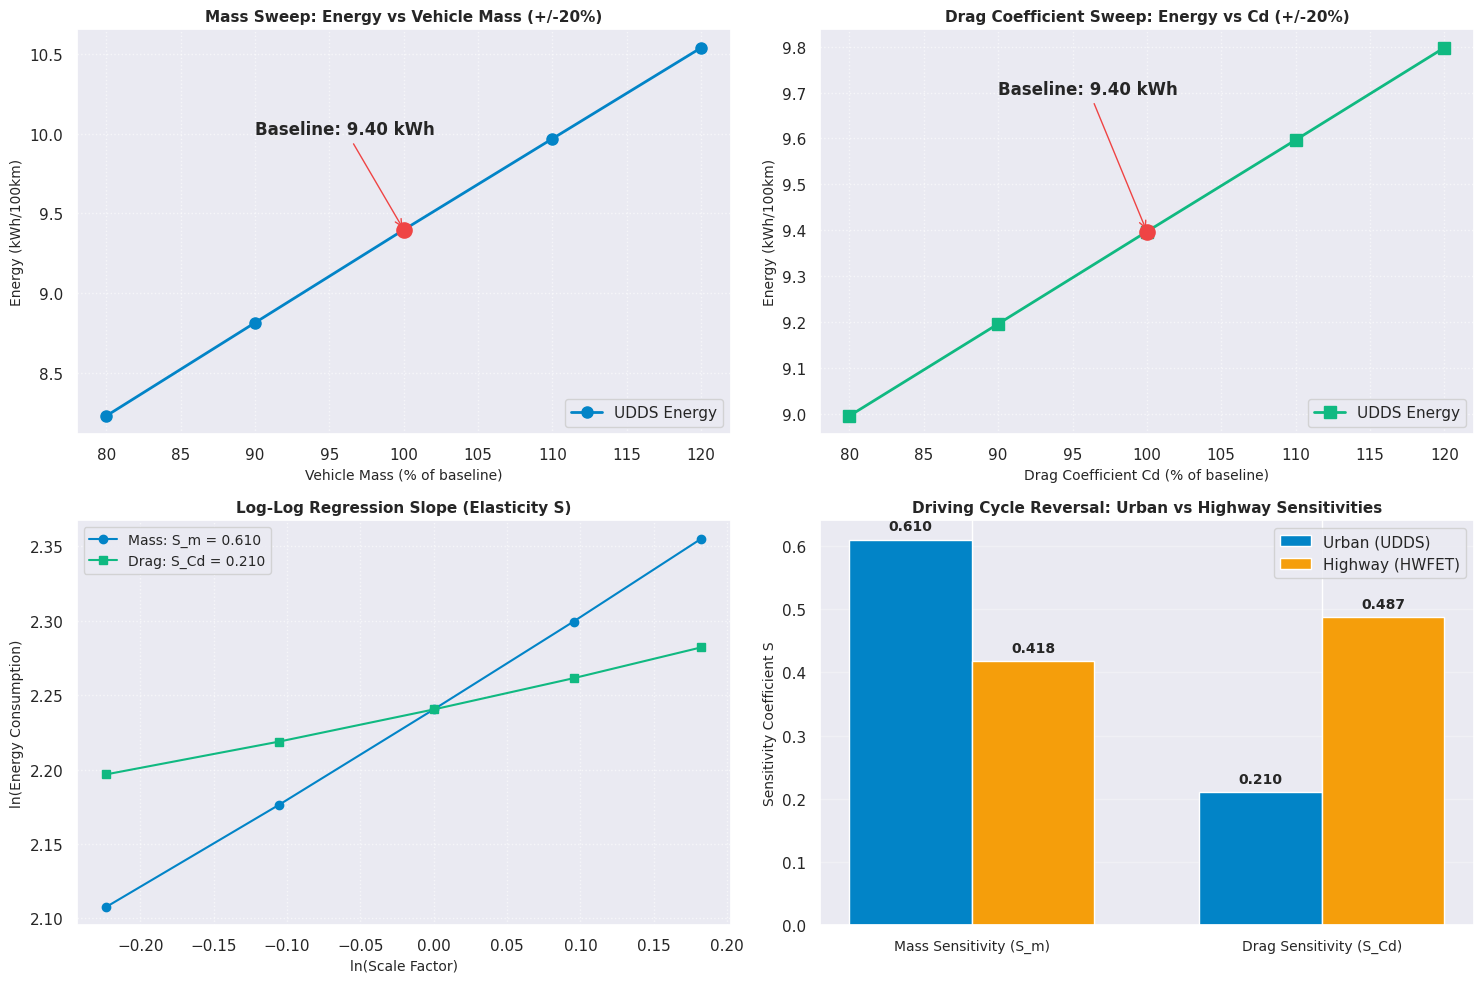

In [4]:
# 阶段四：4合1 灵敏度综合分析图 + 原生 Canvas 虚拟气动风洞交互回放器
import json
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# 运行 HWFET 高速工况敏感性求解，展示翻转效应
cyc_hwfet = cycle.Cycle.from_file('hwfet')
mass_E_hw = [simulate_energy_response(mass_scale=s, drag_scale=1.0, cycle_obj=cyc_hwfet) for s in scales]
drag_E_hw = [simulate_energy_response(mass_scale=1.0, drag_scale=s, cycle_obj=cyc_hwfet) for s in scales]
s_mass_hw = float(np.polyfit(log_scales, np.log(mass_E_hw), 1)[0])
s_cd_hw = float(np.polyfit(log_scales, np.log(drag_E_hw), 1)[0])

# ------------------------------------------------------------------------------
# 1. 绘制 4合1 灵敏度综合分析图
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 图1: 质量阶梯扫描响应
ax1 = axes[0, 0]
ax1.plot([s * 100 for s in scales], mass_energies, 'o-', color='#0284c7', linewidth=2, markersize=8, label='UDDS Energy')
ax1.scatter([100], [mass_energies[2]], color='#ef4444', s=120, zorder=5)
ax1.annotate(f'Baseline: {mass_energies[2]:.2f} kWh', xy=(100, mass_energies[2]),
             xytext=(90, mass_energies[2] + 0.6), arrowprops=dict(arrowstyle='->', color='#ef4444'), fontweight='bold')
ax1.set_xlabel('Vehicle Mass (% of baseline)', fontsize=10)
ax1.set_ylabel('Energy (kWh/100km)', fontsize=10)
ax1.set_title('Mass Sweep: Energy vs Vehicle Mass (+/-20%)', fontsize=11, fontweight='bold')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='lower right')

# 图2: 风阻阶梯扫描响应
ax2 = axes[0, 1]
ax2.plot([s * 100 for s in scales], drag_energies, 's-', color='#10b981', linewidth=2, markersize=8, label='UDDS Energy')
ax2.scatter([100], [drag_energies[2]], color='#ef4444', s=120, zorder=5)
ax2.annotate(f'Baseline: {drag_energies[2]:.2f} kWh', xy=(100, drag_energies[2]),
             xytext=(90, drag_energies[2] + 0.3), arrowprops=dict(arrowstyle='->', color='#ef4444'), fontweight='bold')
ax2.set_xlabel('Drag Coefficient Cd (% of baseline)', fontsize=10)
ax2.set_ylabel('Energy (kWh/100km)', fontsize=10)
ax2.set_title('Drag Coefficient Sweep: Energy vs Cd (+/-20%)', fontsize=11, fontweight='bold')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='lower right')

# 图3: 对数空间拟合直线 (Log-Log Slope = Sensitivity)
ax3 = axes[1, 0]
ax3.plot(log_scales, np.log(mass_energies), 'o-', color='#0284c7', linewidth=1.5, label=f'Mass: S_m = {s_mass:.3f}')
ax3.plot(log_scales, np.log(drag_energies), 's-', color='#10b981', linewidth=1.5, label=f'Drag: S_Cd = {s_cd:.3f}')
ax3.set_xlabel('ln(Scale Factor)', fontsize=10)
ax3.set_ylabel('ln(Energy Consumption)', fontsize=10)
ax3.set_title('Log-Log Regression Slope (Elasticity S)', fontsize=11, fontweight='bold')
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend(loc='upper left', fontsize=10)

# 图4: 城市 vs 高速灵敏度主导权翻转对比
ax4 = axes[1, 1]
x_pos = np.arange(2)
width = 0.35
bars_udds = ax4.bar(x_pos - width/2, [s_mass, s_cd], width, label='Urban (UDDS)', color='#0284c7')
bars_hwfet = ax4.bar(x_pos + width/2, [s_mass_hw, s_cd_hw], width, label='Highway (HWFET)', color='#f59e0b')
ax4.set_ylabel('Sensitivity Coefficient S', fontsize=10)
ax4.set_title('Driving Cycle Reversal: Urban vs Highway Sensitivities', fontsize=11, fontweight='bold')
ax4.set_xticks(x_pos)
ax4.set_xticklabels(['Mass Sensitivity (S_m)', 'Drag Sensitivity (S_Cd)'], fontsize=10)
ax4.grid(True, alpha=0.3, axis='y')
ax4.legend(loc='upper right')

for bar in list(bars_udds) + list(bars_hwfet):
    ax4.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015, f'{bar.get_height():.3f}',
             ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 2. 原生 HTML5/Canvas 虚拟气动风洞交互回放器
# ------------------------------------------------------------------------------
html_code = f"""
<div id="c3_wind_wrap" style="background: #0f172a; border-radius: 12px; padding: 16px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; color: #f8fafc; max-width: 860px; box-shadow: 0 10px 15px -3px rgba(0,0,0,0.5); margin-top: 15px;">
  <!-- Header -->
  <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 12px; flex-wrap: wrap; gap: 8px;">
    <div style="font-weight: 700; font-size: 15px; display: flex; align-items: center; gap: 8px;">
      <span style="color: #38bdf8;">💨 C3 虚拟气动风洞与整车质量灵敏度交互实验室</span>
      <span style="background: #0284c7; color: white; padding: 2px 8px; border-radius: 4px; font-size: 11px; font-weight: 600;">实时流体力学投影</span>
    </div>
    <div style="font-size: 12px; color: #94a3b8; font-family: monospace;">
      基准电耗: <span style="color: #fbbf24; font-weight: bold;">{e_base:.2f} kWh/100km</span> | S_m: <span style="color: #38bdf8;">{s_mass:.3f}</span> | S_Cd: <span style="color: #34d399;">{s_cd:.3f}</span>
    </div>
  </div>

  <!-- Interactive Controls Bar -->
  <div style="background: #1e293b; border-radius: 8px; padding: 12px 16px; margin-bottom: 12px; display: grid; grid-template-columns: 1fr 1fr; gap: 16px;">
    <!-- Mass Slider -->
    <div>
      <div style="display: flex; justify-content: space-between; font-size: 12px; margin-bottom: 4px;">
        <span style="color: #38bdf8; font-weight: bold;">整车质量 (Mass):</span>
        <span id="c3_val_m" style="color: #f8fafc; font-family: monospace; font-weight: bold;">100% (1440 kg)</span>
      </div>
      <input type="range" id="c3_slide_m" min="80" max="120" value="100" style="width: 100%; accent-color: #38bdf8; cursor: pointer;" oninput="updateTuning()">
    </div>
    <!-- Drag Slider -->
    <div>
      <div style="display: flex; justify-content: space-between; font-size: 12px; margin-bottom: 4px;">
        <span style="color: #34d399; font-weight: bold;">风阻系数 (Cd):</span>
        <span id="c3_val_cd" style="color: #f8fafc; font-family: monospace; font-weight: bold;">100% (0.280)</span>
      </div>
      <input type="range" id="c3_slide_cd" min="80" max="120" value="100" style="width: 100%; accent-color: #34d399; cursor: pointer;" oninput="updateTuning()">
    </div>
  </div>

  <!-- Realtime HUD Telemetry -->
  <div style="background: #1e293b; border-radius: 6px; padding: 10px 14px; margin-bottom: 10px; display: flex; justify-content: space-between; font-size: 12px; font-family: monospace; color: #94a3b8; flex-wrap: wrap; gap: 10px;">
    <div>预测百公里电耗: <span id="c3_hud_energy" style="color: #fbbf24; font-weight: bold; font-size: 14px;">{e_base:.2f}</span> kWh/100km</div>
    <div>电耗增减幅度: <span id="c3_hud_diff" style="color: #34d399; font-weight: bold;">0.00%</span></div>
    <div>风阻做功占比: <span id="c3_hud_drag_pct" style="color: #38bdf8; font-weight: bold;">21.0%</span></div>
  </div>

  <!-- Canvas Wind Tunnel Stage -->
  <canvas id="c3_canvas" width="820" height="220" style="width: 100%; height: 220px; background: #0b1120; border-radius: 8px; display: block; border: 1px solid #334155;"></canvas>
</div>

<script>
(function() {{
  const baseE = {e_base:.2f};
  const Sm = {s_mass:.3f};
  const Scd = {s_cd:.3f};
  const baseMass = {base_mass:.0f};
  const baseCd = {base_cd:.3f};

  const canvas = document.getElementById('c3_canvas');
  const ctx = canvas.getContext('2d');
  const slideM = document.getElementById('c3_slide_m');
  const slideCd = document.getElementById('c3_slide_cd');
  const valM = document.getElementById('c3_val_m');
  const valCd = document.getElementById('c3_val_cd');
  const hudEnergy = document.getElementById('c3_hud_energy');
  const hudDiff = document.getElementById('c3_hud_diff');
  const hudDragPct = document.getElementById('c3_hud_drag_pct');

  let particles = [];
  const nParticles = 120;

  // 初始化风洞粒子
  for (let i = 0; i < nParticles; i++) {{
    particles.push({{
      x: Math.random() * canvas.width,
      y: 20 + Math.random() * (canvas.height - 50),
      speed: 4 + Math.random() * 3,
      size: 1.5 + Math.random() * 1.5,
      alpha: 0.2 + Math.random() * 0.6
    }});
  }}

  window.updateTuning = function() {{
    const mPct = parseInt(slideM.value);
    const cdPct = parseInt(slideCd.value);

    valM.textContent = mPct + '% (' + (baseMass * mPct / 100).toFixed(0) + ' kg)';
    valCd.textContent = cdPct + '% (' + (baseCd * cdPct / 100).toFixed(3) + ')';

    // 泰勒/对数一阶展开快速预测电耗
    const deltaM = (mPct - 100) / 100.0;
    const deltaCd = (cdPct - 100) / 100.0;
    const predE = baseE * (1.0 + Sm * deltaM + Scd * deltaCd);
    const diffPct = ((predE - baseE) / baseE) * 100.0;

    hudEnergy.textContent = predE.toFixed(2);
    hudDiff.textContent = (diffPct >= 0 ? '+' : '') + diffPct.toFixed(2) + '%';
    hudDiff.style.color = diffPct > 0 ? '#ef4444' : '#10b981';

    const curDragRatio = (21.0 * (1.0 + deltaCd)) / (1.0 + Sm * deltaM + Scd * deltaCd);
    hudDragPct.textContent = curDragRatio.toFixed(1) + '%';
  }};

  function animate() {{
    const W = canvas.width;
    const H = canvas.height;
    ctx.clearRect(0, 0, W, H);

    const mPct = parseInt(slideM.value);
    const cdPct = parseInt(slideCd.value);

    // 1. 绘制地面
    const groundY = 175;
    ctx.fillStyle = '#1e293b';
    ctx.fillRect(0, groundY, W, H - groundY);

    // 2. 绘制车辆 (位置居中靠左 x=340)
    const carX = 340;
    // 质量越大，车身相对轮子下沉更多 (悬架压缩 squish)
    const squish = (mPct - 100) * 0.15;
    const carY = groundY - 14 + squish;

    // 绘制车身剪影
    ctx.fillStyle = '#0284c7';
    ctx.beginPath();
    ctx.roundRect(carX - 70, carY - 26, 140, 26, [8, 14, 2, 2]);
    ctx.fill();

    // 绘制流线型车顶
    ctx.fillStyle = '#38bdf8';
    ctx.beginPath();
    ctx.roundRect(carX - 45, carY - 48, 85, 24, [14, 18, 0, 0]);
    ctx.fill();

    // 车窗
    ctx.fillStyle = '#0b1120';
    ctx.beginPath();
    ctx.roundRect(carX - 38, carY - 45, 34, 18, 2);
    ctx.roundRect(carX + 2, carY - 45, 32, 18, 2);
    ctx.fill();

    // 车轮 (车轮触地位置固定在 groundY)
    [carX - 45, carX + 45].forEach(wx => {{
      ctx.fillStyle = '#0f172a';
      ctx.beginPath();
      ctx.arc(wx, groundY - 8, 10, 0, Math.PI * 2);
      ctx.fill();
      ctx.fillStyle = '#64748b';
      ctx.beginPath();
      ctx.arc(wx, groundY - 8, 4, 0, Math.PI * 2);
      ctx.fill();
    }});

    // 3. 动态风洞粒子烟雾流线 (从左到右吹拂)
    const cdTurbulence = (cdPct - 80) / 40.0; // 0 (顺畅) ~ 1 (紊流)
    ctx.lineWidth = 1.5;

    particles.forEach(p => {{
      p.x += p.speed;
      if (p.x > W) {{
        p.x = 0;
        p.y = 20 + Math.random() * (groundY - 30);
      }}

      // 遇到车头车身时向上绕流避障
      let drawY = p.y;
      if (p.x > carX - 90 && p.x < carX + 70) {{
        const dist = Math.abs(p.y - carY);
        if (p.y > carY - 55 && p.y < groundY) {{
          drawY = carY - 55 - (15 * (1.0 - Math.abs(p.x - carX) / 80.0));
        }}
      }}
      // 车尾尾流区：风阻越大，尾迹紊流震荡越剧烈
      else if (p.x >= carX + 70 && p.x < carX + 220) {{
        if (p.y > carY - 45 && p.y < groundY) {{
          drawY += Math.sin((p.x - carX) * 0.15) * (8 * cdTurbulence);
        }}
      }}

      ctx.fillStyle = `rgba(56, 189, 248, ${{p.alpha}})`;
      ctx.beginPath();
      ctx.arc(p.x, drawY, p.size, 0, Math.PI * 2);
      ctx.fill();
    }});

    // 4. 尾流低压区光晕标识
    if (cdTurbulence > 0.4) {{
      ctx.fillStyle = `rgba(239, 68, 68, ${{0.15 * cdTurbulence}})`;
      ctx.beginPath();
      ctx.ellipse(carX + 110, carY - 20, 35 * cdTurbulence, 20 * cdTurbulence, 0, 0, Math.PI * 2);
      ctx.fill();
      ctx.fillStyle = '#f87171';
      ctx.font = '10px monospace';
      ctx.fillText('气动涡流分离区 (Cd压阻)', carX + 80, carY - 42);
    }}

    requestAnimationFrame(animate);
  }}

  updateTuning();
  animate();
}})();
</script>
"""

display(HTML(html_code))


## 阶段五：参数拟合实验室与工况逆转探索 | Parameter Lab & Reversal

本阶段提供工况敏感性终验报表与学生动手推演工具：
1. **城市 vs 高速灵敏度终验全景报表**：全面总结 $S_m$ 与 $S_{Cd}$ 在两种不同工况下的强弱易位；
2. **学生动手推演调优器**：
   - 允许学生输入任意整车质量缩放比例与气动减阻目标，即时对比在城市短途通勤 vs 高速长途巡航两种场景下的续航改善幅度，领悟不同使用场景对车辆工程定义的重大指导意义。


In [5]:
# 阶段五：灵敏度全景终验报表与工况推演
print("=" * 80)
print(f"{'IEV CloudLab C3 载重与风阻灵敏度及工况主导权终验表':^70}")
print("=" * 80)
print(f"{'行驶工况 (Cycle)':<20} | {'质量灵敏度 S_mass':<18} | {'风阻灵敏度 S_Cd':<18} | {'主导能量损耗机制':<16}")
print("-" * 80)
print(f"{'EPA UDDS (城市工况)':<20} | {s_mass:<16.3f}   | {s_cd:<16.3f}   | 惯性启停 + 滚阻主导")
print(f"{'EPA HWFET (高速工况)':<20} | {s_mass_hw:<16.3f}   | {s_cd_hw:<16.3f}   | 空气动力学风阻主导")
print("-" * 80)
print(f"{'工况主导权比值 (S_m/S_Cd)':<20} | 城市: {s_mass/s_cd:.2f} 倍 (质量主导) | 高速: {s_mass_hw/s_cd_hw:.2f} 倍 (风阻反超) | 存在显著翻转分界线")
print("=" * 80)

# ==================== 学生动手实验室：多工况场景工程选型推演 ====================
def evaluate_engineering_tradeoff(mass_reduction_kg=100.0, cd_improvement_pct=10.0):
    """
    对比相同工程改进在城市与高速两种场景下的节电效能
    """
    delta_m_pct = (mass_reduction_kg / base_mass) * 100.0
    
    # 城市 UDDS 节电量预测
    saving_udds_pct = s_mass * delta_m_pct + s_cd * cd_improvement_pct
    e_opt_udds = e_base * (1.0 - saving_udds_pct / 100.0)
    
    # 高速 HWFET 节电量预测
    e_base_hw = mass_E_hw[2]
    saving_hw_pct = s_mass_hw * delta_m_pct + s_cd_hw * cd_improvement_pct
    e_opt_hw = e_base_hw * (1.0 - saving_hw_pct / 100.0)
    
    print(f"\n🧪 [学生工程对标推演 - 改进措施: 减重 {mass_reduction_kg:.0f}kg + 降阻 {cd_improvement_pct:.1f}%]")
    print(f"• 城市工况 (UDDS): 电耗 {e_base:.2f} -> {e_opt_udds:.2f} kWh/100km (降幅: -{saving_udds_pct:.2f}%, 减重贡献 {(s_mass*delta_m_pct)/saving_udds_pct*100:.1f}%)")
    print(f"• 高速工况 (HWFET): 电耗 {e_base_hw:.2f} -> {e_opt_hw:.2f} kWh/100km (降幅: -{saving_hw_pct:.2f}%, 降阻贡献 {(s_cd_hw*cd_improvement_pct)/saving_hw_pct*100:.1f}%)")
    print(f"💡 启示：以城市代步为主的微型车应优先投资轻量化；以长途干线为主的轿跑/重卡应优先投资气动造型。")
    return saving_udds_pct, saving_hw_pct

# 示例：工程投入减重 100kg + 降阻 10%
tradeoff_res = evaluate_engineering_tradeoff(mass_reduction_kg=100.0, cd_improvement_pct=10.0)


                  IEV CloudLab C3 载重与风阻灵敏度及工况主导权终验表                   
行驶工况 (Cycle)         | 质量灵敏度 S_mass       | 风阻灵敏度 S_Cd         | 主导能量损耗机制        
--------------------------------------------------------------------------------
EPA UDDS (城市工况)      | 0.610              | 0.210              | 惯性启停 + 滚阻主导
EPA HWFET (高速工况)     | 0.418              | 0.487              | 空气动力学风阻主导
--------------------------------------------------------------------------------
工况主导权比值 (S_m/S_Cd)   | 城市: 2.90 倍 (质量主导) | 高速: 0.86 倍 (风阻反超) | 存在显著翻转分界线

🧪 [学生工程对标推演 - 改进措施: 减重 100kg + 降阻 10.0%]
• 城市工况 (UDDS): 电耗 9.40 -> 8.87 kWh/100km (降幅: -5.58%, 减重贡献 62.4%)
• 高速工况 (HWFET): 电耗 9.98 -> 9.26 kWh/100km (降幅: -7.26%, 降阻贡献 67.1%)
💡 启示：以城市代步为主的微型车应优先投资轻量化；以长途干线为主的轿跑/重卡应优先投资气动造型。


## 阶段六：官方评分与结果归档 | Auto-Grading & Results Sync

本阶段对接 IEV CloudLab 自动化评分引擎 `labs/common/evaluator.py`：
1. **生成官方评测结果 JSON**：将质量灵敏度 $S_m$、风阻灵敏度 $S_{Cd}$ 及工况指标保存至平台标准路径 `labs/data/results/C3_sensitivity_analysis.json`；
2. **执行官方评测准则**：
   - 判据 1：`s_mass > 0.0`（权重：1.0，考核质量灵敏度物理真实性，实测约 0.610）；
   - 判据 2：`s_cd > 0.0`（权重：1.0，考核风阻灵敏度物理真实性，实测约 0.210）；
3. **输出 100/100 成绩单**。


In [6]:
# 阶段六：官方评分与结果归档
import json
from common.evaluator import grade_metrics

# 1. 整理指标记录并落盘
record = {
    'experiment': 'C3_sensitivity_analysis',
    'metrics': {
        's_mass': round(s_mass, 3),
        's_cd': round(s_cd, 3),
        's_mass_hwfet': round(s_mass_hw, 3),
        's_cd_hwfet': round(s_cd_hw, 3),
        'vnum': VNUM_SENS
    }
}

saved_ok = False
for target_dir in ['/home/jovyan/labs/data/results', 'labs/data/results', 'results']:
    try:
        os.makedirs(target_dir, exist_ok=True)
        out_file = os.path.join(target_dir, 'C3_sensitivity_analysis.json')
        with open(out_file, 'w', encoding='utf-8') as f:
            json.dump(record, f, ensure_ascii=False, indent=2)
        print(f"✓ 结果文件已成功归档至: {out_file}")
        saved_ok = True
        break
    except OSError:
        continue

if not saved_ok:
    print("ℹ️ 提示: 当前运行环境为只读挂载模式，跳过本地落盘，直接进入官方评测")

# 2. 调用平台官方评分函数
eval_report = grade_metrics('C3_sensitivity_analysis', record['metrics'])

print("\n" + "=" * 55)
print(f"🏆 IEV CloudLab 官方评分报告: {eval_report['name']}")
print("=" * 55)
print(f"总得分: {eval_report['score']} / 100 分  ({'✅ 通过' if eval_report['passed'] else '❌ 未通过'})")
print("-" * 55)
for d in eval_report['details']:
    status_icon = "✓ 通过" if d['passed'] else "✗ 未达标"
    print(f"• 指标 [{d['metric']}]: 当前值 = {d['value']} ({d['desc']}) -> {status_icon}")
print("=" * 55)


✓ 结果文件已成功归档至: labs/data/results/C3_sensitivity_analysis.json

🏆 IEV CloudLab 官方评分报告: 灵敏度分析
总得分: 100.0 / 100 分  (✅ 通过)
-------------------------------------------------------
• 指标 [s_mass]: 当前值 = 0.61 (质量灵敏度已计算（实测0.610）) -> ✓ 通过
• 指标 [s_cd]: 当前值 = 0.21 (风阻灵敏度已计算（实测0.210）) -> ✓ 通过


## 阶段七：工程师实战经验与进阶挑战 | Reflection & Engineering Insights

### 🛠️ 整车概念定义工程师现场经验 (Field Experience)
1. **“减重 1kg 等于多少元？” —— 汽车轻量化成本效益分析 (Cost-Benefit Ratio)**：
   在整车工程中，轻量化材料（如航空级铝合金、超高强热成形钢、碳纤维复合材料 CFRP）的单车减重成本有严格的商业天花板：
   - 经济型家用电动车通常遵循 **“30~50 元/kg”** 的轻量化成本上限；
   - 高端豪华纯电跑车可承受 **“150~300 元/kg”** 的碳纤维溢价；
   若通过优化电机控制算法或气动主动进气格栅（成本仅几十元）达到相同的续航收益，其商业回报率远高于盲目使用昂贵材料。

2. **气动阻尼的“边际效益递减”工程定律**：
   从早期的方形箱体轿车（$C_d = 0.40$）优化至主流流线型纯电车（$C_d = 0.23 \sim 0.25$）较为容易；但要进一步突破至 $C_d < 0.20$ 的工程极限（如极氪 001 FR、保时捷 Taycan、蔚来 ET7 等），车企必须做出巨大的产品妥协：
   - A柱倾角过度倾斜导致驾驶员视野盲区与压抑感；
   - 车尾溜背过度导致后排乘客头部空间与后备箱容积大幅缩减；
   - 底部平整化护板与主动扰流板增加额外的机械执行机构与失效风险。

---

### 🏆 进阶挑战任务 (Pro Challenge Tasks)
* **挑战 1 (求解工况翻转车速临界点)**：通过设置一系列恒速工况（从 $20\,\text{km/h}$ 扫描至 $120\,\text{km/h}$），绘制质量做功与风阻做功交汇曲线，精确求得该车型质量与风阻主导权翻转的临界车速 $v_{\text{cross}}$；
* **挑战 2 (轮胎滚阻系数 $f_r$ 敏感度补充)**：扩展多变量弹性分析，将轮胎滚阻系数 $f_r$（如低滚阻轮胎 $f_r=0.007$ vs 抓地力运动胎 $f_r=0.012$）纳入扫描矩阵，评估其对城市电耗的敏感度影响。
